# Phase 2: Liver segmentation (charvi, patient 1)

| | This member's algorithms |
|---|---|
| Morphology | custom **cross** and hand-made **octagon** structuring elements |
| Method A | **adaptive local thresholding** (`threshold_local`) + morphology |
| Method B | **seeded region growing** from an automatic seed |
| Validation | Dice + IoU against the ground-truth liver |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

from scipy import ndimage as ndi
from skimage.filters import threshold_local

NAME = "charvi"
ENH = "../phase1/outputs_charvi/enhanced"
GT = f"../data/slices/{NAME}"
OUT = "outputs_charvi"
FIGS = "../report/figures/charvi"
FAILED = "../report/failed_cases/charvi"
for d in [f"{OUT}/adaptive", f"{OUT}/regiongrow", FIGS, FAILED]:
    os.makedirs(d, exist_ok=True)

files = sorted(glob.glob(f"{ENH}/*_enh.png"))
print(len(files), "enhanced slices found")

def load(p):
    sid = os.path.basename(p).replace("_enh.png", "")
    return sid, cv2.imread(p, 0), cv2.imread(f"{GT}/{sid}_liver.png", 0) > 0

def dice(pred, gt):
    """Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none."""
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum() + 1e-9)

def iou(pred, gt):
    """Jaccard / IoU = |A n B| / |A u B|."""
    return (pred & gt).sum() / ((pred | gt).sum() + 1e-9)

def overlay(img, pred, gt):
    """RED = predicted outline, GREEN = ground-truth outline."""
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for mask, colour in [(gt, (0, 255, 0)), (pred, (255, 0, 0))]:
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, colour, 2)
    return rgb

def keep_liver(mask):
    """Biggest blob on the image's left side (the liver is on the patient's right)."""
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    best, best_area = 0, 0
    for i in range(1, n):
        if centroids[i][0] < 0.6 * mask.shape[1] and stats[i, cv2.CC_STAT_AREA] > best_area:
            best, best_area = i, stats[i, cv2.CC_STAT_AREA]
    return labels == best if best else np.zeros(mask.shape, bool)

example = max(files, key=lambda f: load(f)[2].sum())
sid, img, gt = load(example)
print("example slice:", sid)

18 enhanced slices found
example slice: p1_s65


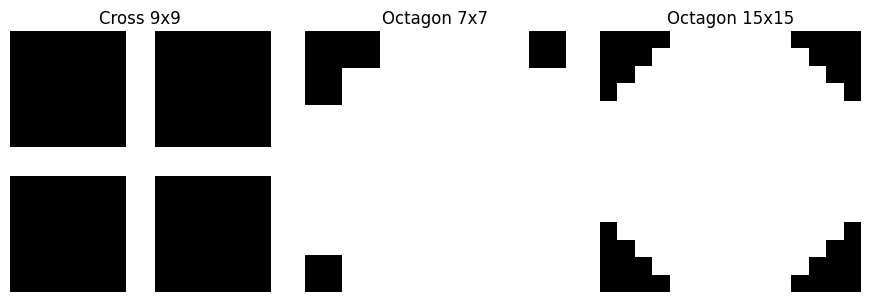

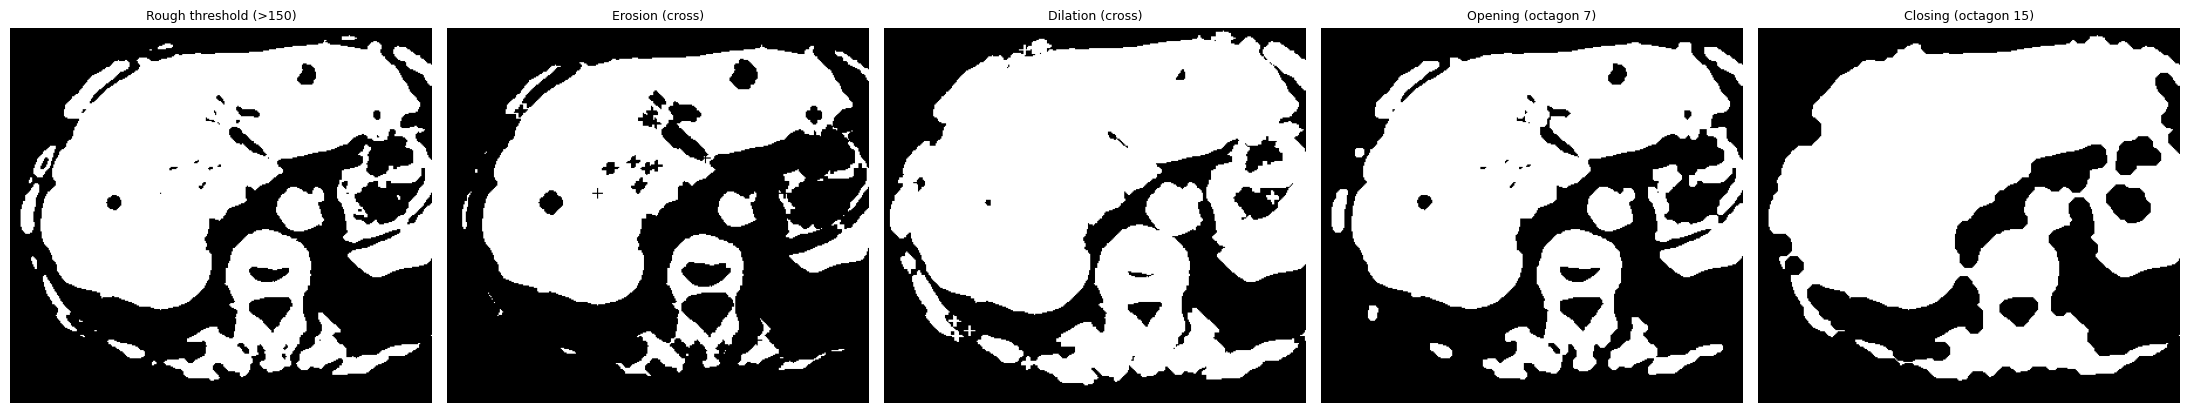

In [2]:
SE_CROSS_9 = cv2.getStructuringElement(cv2.MORPH_CROSS, (9, 9))
SE_OCTAGON_15 = np.ones((15, 15), np.uint8)                       # hand-made octagon: square with cut corners
for r in range(15):
    for c in range(15):
        if min(r, 14 - r) + min(c, 14 - c) < 4:
            SE_OCTAGON_15[r, c] = 0
SE_OCTAGON_7 = cv2.resize(SE_OCTAGON_15, (7, 7), interpolation=cv2.INTER_NEAREST)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, se, t in zip(ax, [SE_CROSS_9, SE_OCTAGON_7, SE_OCTAGON_15], ["Cross 9x9", "Octagon 7x7", "Octagon 15x15"]):
    a.imshow(se, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

rough = (img > 150).astype(np.uint8)
ops = {"Rough threshold (>150)": rough,
       "Erosion (cross)": cv2.erode(rough, SE_CROSS_9),
       "Dilation (cross)": cv2.dilate(rough, SE_CROSS_9),
       "Opening (octagon 7)": cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_OCTAGON_7),
       "Closing (octagon 15)": cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_OCTAGON_15)}
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, (t, m) in zip(ax, ops.items()):
    a.imshow(m[100:420, 40:400], cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_morphology.png", dpi=120); plt.show()

**Method A: adaptive local thresholding.** Instead of one threshold for the whole image, every pixel gets its own threshold = the mean brightness of the 251x251 window around it. A pixel counts as "liver-like" if it is brighter than its local mean and brighter than 120 (to ignore fat and muscle). Morphology then cuts thin links, `keep_liver` keeps the liver blob, and closing + hole filling tidy it.

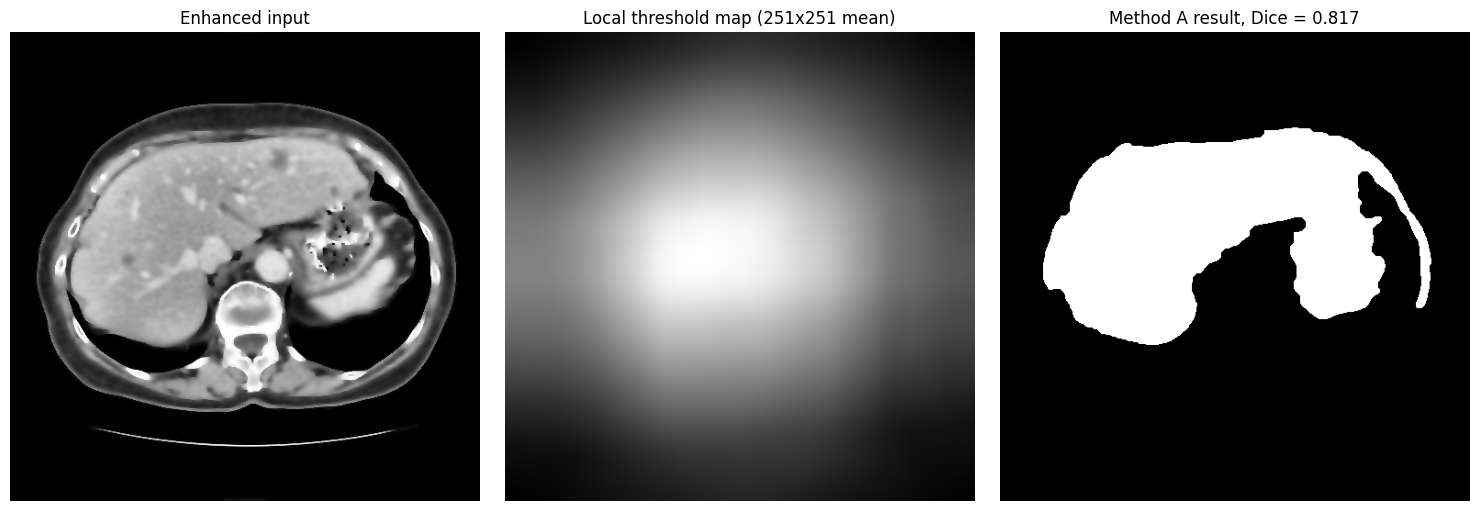

In [3]:
def segment_adaptive(img, block=251, floor=120):
    t = threshold_local(img, block_size=block, method="mean", offset=0)     # one threshold per pixel
    mask = ((img > t) & (img > floor)).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, SE_OCTAGON_7)
    mask = keep_liver(mask > 0)
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, SE_OCTAGON_15)
    return ndi.binary_fill_holes(mask > 0)

local_t = threshold_local(img, block_size=251, method="mean")
pred_a = segment_adaptive(img)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Enhanced input")
ax[1].imshow(local_t, cmap="gray"); ax[1].set_title("Local threshold map (251x251 mean)")
ax[2].imshow(pred_a, cmap="gray"); ax[2].set_title(f"Method A result, Dice = {dice(pred_a, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_a_adaptive.png", dpi=120); plt.show()

**Method B: seeded region growing.** 1) Find a seed automatically: the pixel deepest inside the solid liver-coloured area (largest distance-transform value). 2) Grow outwards, adding neighbours whose brightness is within 30 of the region's average. 3) Clean up with opening, `keep_liver`, closing and hole filling.

In [4]:
def region_grow(img, seed, tolerance, allowed=None):
    """Seeded region growing: start at the seed pixel and keep adding 4-neighbours whose
    brightness is within `tolerance` of the region's running average."""
    h, w = img.shape
    region = np.zeros((h, w), bool)
    region[seed] = True
    stack, total, count = [seed], float(img[seed]), 1
    while stack:
        y, x = stack.pop()
        for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            yy, xx = y + dy, x + dx
            if 0 <= yy < h and 0 <= xx < w and not region[yy, xx] and (allowed is None or allowed[yy, xx]):
                if abs(float(img[yy, xx]) - total / count) <= tolerance:
                    region[yy, xx] = True
                    stack.append((yy, xx))
                    total += float(img[yy, xx]); count += 1
    return region

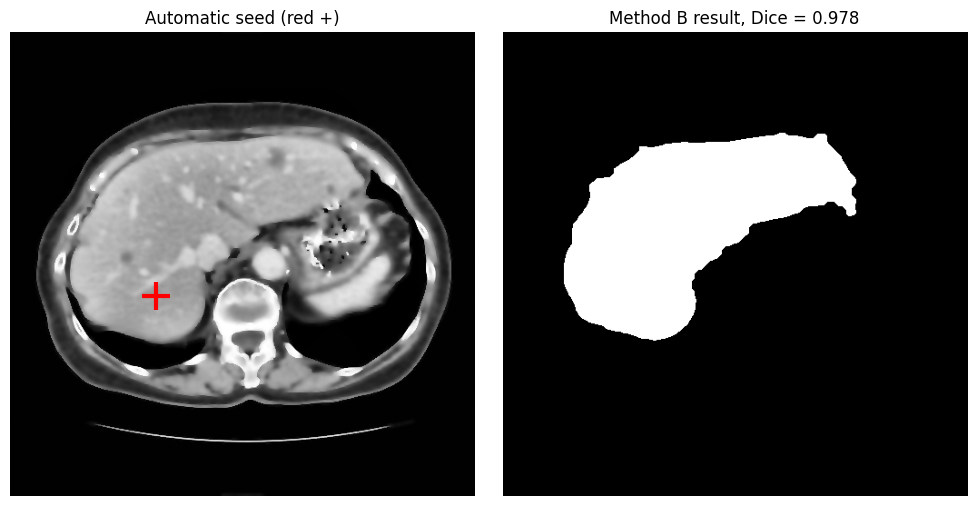

In [5]:
LIVER_LOW, LIVER_HIGH, TOLERANCE = 150, 225, 30

def find_seed(img):
    band = ((img >= LIVER_LOW) & (img <= LIVER_HIGH)).astype(np.uint8)
    core = keep_liver(cv2.morphologyEx(band, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))))
    if not core.any():
        return None
    dist = cv2.distanceTransform(core.astype(np.uint8), cv2.DIST_L2, 5)
    return np.unravel_index(dist.argmax(), dist.shape)               # deepest point inside the core

def segment_region_growing(img):
    seed = find_seed(img)
    if seed is None:
        return np.zeros(img.shape, bool)
    grown = region_grow(cv2.GaussianBlur(img, (5, 5), 0), seed, TOLERANCE)
    mask = cv2.morphologyEx(grown.astype(np.uint8), cv2.MORPH_OPEN, SE_OCTAGON_7) > 0
    mask = cv2.morphologyEx(keep_liver(mask).astype(np.uint8), cv2.MORPH_CLOSE, SE_OCTAGON_15)
    return ndi.binary_fill_holes(mask > 0)

seed = find_seed(img)
pred_b = segment_region_growing(img)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap="gray"); ax[0].plot(seed[1], seed[0], "r+", markersize=20, mew=3); ax[0].set_title("Automatic seed (red +)")
ax[1].imshow(pred_b, cmap="gray"); ax[1].set_title(f"Method B result, Dice = {dice(pred_b, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_b_regiongrow.png", dpi=120); plt.show()

In [6]:
rows = []
for f in files:
    sid, img, gt = load(f)
    for method, fn in [("adaptive", segment_adaptive), ("regiongrow", segment_region_growing)]:
        pred = fn(img)
        cv2.imwrite(f"{OUT}/{method}/{sid}_liver_pred.png", pred.astype(np.uint8) * 255)
        rows.append({"slice": sid, "method": method, "Dice": dice(pred, gt), "IoU": iou(pred, gt), "GT liver pixels": int(gt.sum())})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase2_metrics.csv", index=False)
print(results.groupby("method")[["Dice", "IoU"]].agg(["mean", "std", "min"]).round(3))
print("\nPer slice Dice:")
print(results.pivot(index="slice", columns="method", values="Dice").round(3))

             Dice                 IoU             
             mean    std   min   mean    std   min
method                                            
adaptive    0.756  0.204  0.02  0.637  0.191  0.01
regiongrow  0.880  0.225  0.00  0.827  0.223  0.00

Per slice Dice:
method  adaptive  regiongrow
slice                       
p1_s56     0.834       0.829
p1_s57     0.503       0.911
p1_s58     0.851       0.850
p1_s59     0.811       0.956
p1_s60     0.808       0.959
p1_s61     0.724       0.960
p1_s62     0.759       0.957
p1_s63     0.769       0.964
p1_s64     0.812       0.975
p1_s65     0.817       0.978
p1_s66     0.829       0.961
p1_s67     0.874       0.974
p1_s68     0.877       0.949
p1_s69     0.913       0.962
p1_s70     0.844       0.881
p1_s71     0.832       0.946
p1_s72     0.725       0.828
p1_s73     0.020       0.000


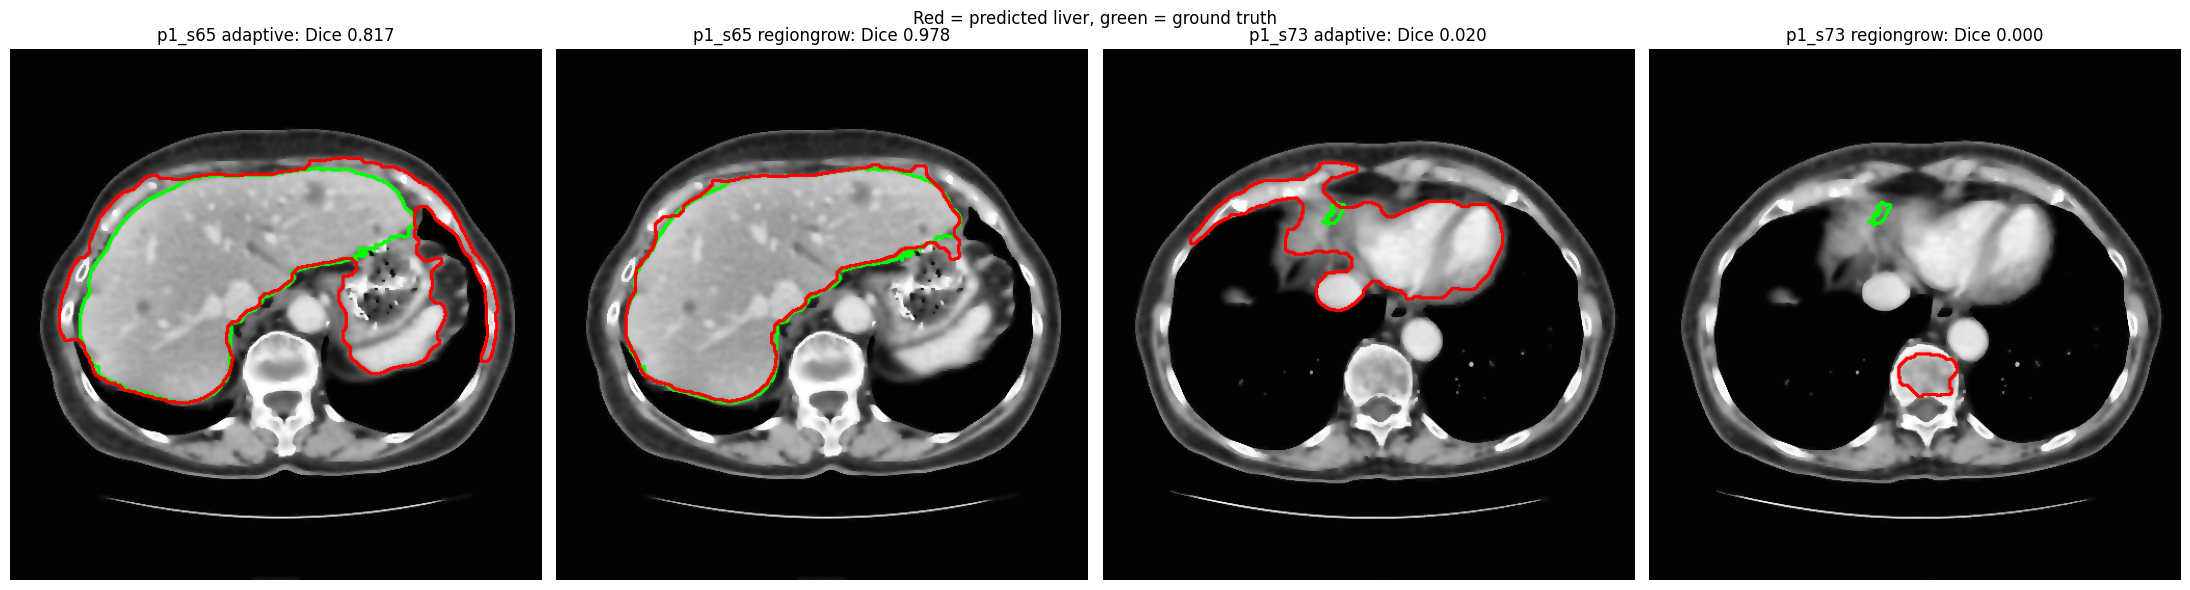

In [7]:
rg = results[results.method == "regiongrow"].set_index("slice")["Dice"]
best_sid, worst_sid = rg.idxmax(), rg.idxmin()
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, (s, method) in zip(ax, [(best_sid, "adaptive"), (best_sid, "regiongrow"), (worst_sid, "adaptive"), (worst_sid, "regiongrow")]):
    _, img, gt = load(f"{ENH}/{s}_enh.png")
    pred = cv2.imread(f"{OUT}/{method}/{s}_liver_pred.png", 0) > 0
    a.imshow(overlay(img, pred, gt)); a.axis("off"); a.set_title(f"{s} {method}: Dice {dice(pred, gt):.3f}")
plt.suptitle("Red = predicted liver, green = ground truth")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_overlays.png", dpi=120); plt.show()

In [8]:
# ---- failed cases: every slice where the best method scored Dice < 0.7, with the likely reason ----
def failure_reason(pred, gt):
    if pred.sum() == 0:
        return "missed completely: nothing was segmented"
    if gt.sum() < 3000:
        return f"very small liver on this slice ({int(gt.sum())} pixels), near the top or bottom of the organ"
    if pred.sum() > 1.5 * gt.sum():
        return "over-segmentation: the mask leaked into neighbouring tissue"
    if pred.sum() < 0.6 * gt.sum():
        return "under-segmentation: only part of the liver was found"
    return "boundary mismatch: right place, but the outline differs from the ground truth"

best_method = results.groupby("method")["Dice"].mean().idxmax()
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]
lines = [f"# Phase 2 failed cases: {NAME} (liver segmentation)", "",
         f"Best method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.", "",
         "| Slice | Dice ({}) | Ground-truth pixels | Predicted pixels | Likely reason |".format(best_method),
         "|---|---|---|---|---|"]
for _, row in failed.iterrows():
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_liver_pred.png", 0) > 0
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt.sum())} | {int(pred.sum())} | {failure_reason(pred, gt)} |")
for _, row in failed.head(3).iterrows():                       # save overlays of the 3 worst
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_liver_pred.png", 0) > 0
    cv2.imwrite(f"{FAILED}/{NAME}_{row.slice}_{best_method}_overlay.png", cv2.cvtColor(overlay(img, pred, gt), cv2.COLOR_RGB2BGR))
if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines += ["", "Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth)."]
open(f"{FAILED}/{NAME}_phase2_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Phase 2 failed cases: charvi (liver segmentation)

Best method: **regiongrow** (mean Dice 0.880). Slices with Dice < 0.7: 1 of 18.

| Slice | Dice (regiongrow) | Ground-truth pixels | Predicted pixels | Likely reason |
|---|---|---|---|---|
| p1_s73 | 0.000 | 211 | 1850 | very small liver on this slice (211 pixels), near the top or bottom of the organ |

Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth).
